# Tatsoi image-environment dataset — feature-level trait recognition baseline (reproduction)

**Paper**: *A time-resolved image-environment dataset for tatsoi growth monitoring and intelligent phytoprotection benchmarking*, Frontiers in Plant Science Vol. 17 (Data Report), DOI [10.3389/fpls.2026.1978055](https://doi.org/10.3389/fpls.2026.1978055).
**Dataset**: Mendeley Data Parts 1–4, DOIs 10.17632/2kfszcxhw6.1, 10.17632/rvd2mxrrxj.1, 10.17632/657hywkz9x.1, 10.17632/286gv4tmrh.1 (CC BY-NC 4.0 / CC BY 4.0). Author training/benchmark code is bundled with Part 1.

**Purpose**: reproduce the paper's *supplemental feature-level image-environment trait recognition baseline* (Section 3.4, Table 4). The authors released their own baseline script (`scripts/run_baseline_models.py`, bundled in the part00 core zip); this notebook runs that author code unchanged: it extracts 27 canopy morphology + color features from the Labelme polygons and images, and evaluates Dummy / logistic regression / random forest / HistGradientBoosting classifiers on the seven plant-level traits under the three released splits (random, temporal, plant-holdout). It then reproduces the paper's environment-feature comparison by adding the 96 released environmental features to the same pipeline.

**Scope**: full-dataset rerun of the author's classical feature-level baseline (all 3,456 images, 128 plants, 27 dates, seed 42). The deep-learning benchmarks in the paper (YOLOv8, RT-DETR, ResNet50/Swin-T trait classifiers, Grad-CAM) are out of scope. A rerun of a published baseline with the authors' own code checks reproducibility of Table 4; it does not re-verify the paper's dataset-level claims beyond that.

**Execution status**: executed and validated on a Google Colab **CPU** runtime (no GPU is needed; sklearn tabular models only).

**参考 (Japanese summary)**: このノートブックは、タツォイ画像・環境データセット論文の補足「特徴量レベルの形質認識ベースライン」を、著者公開コード (`run_baseline_models.py`) をそのまま使って全画像 (3,456 枚) で再実行します。CPU ランタイムのみで動作します (GPU 不要)。ランタイム種別は「CPU」を選択してください。

## Runtime selection and how to run

**Select the Colab runtime type: `CPU` (recommended — this notebook needs no GPU).**
Use `Runtime > Run all` to execute everything top to bottom.

**Expected cost (measured on the validation run, 2026-11-27):** ~32 GiB of downloads (the five dataset zips; the four image archives are unavoidably large because the authors' color features are computed from the full-resolution photographs), ~50–80 minutes end to end on a standard CPU runtime, mostly download and feature-extraction time. Model training itself takes only a few minutes.

**Limitations**: single seed (42, as in the paper); image-level features follow the authors' exact definitions; the +environment extension reuses the authors' own evaluation code with the 96 released environmental feature columns, and is the only step not present verbatim in the released baseline script.

**実行方法と所要時間**: ランタイムは「CPU」を選択してください。ダウンロード約 32 GiB、全体で 50〜80 分程度かかります (モデル学習自体は数分)。

### Check the environment

The author code needs `numpy`, `pandas`, `pillow` and `scikit-learn>=1.2` (its `requirements.txt`), all preinstalled on Colab. We print the interpreter and library versions actually used, and fix the global random seed to 42 as in the paper's benchmarks.
環境とライブラリ版本を確認し、シードを 42 に固定します。

In [ ]:
import sys, random
import numpy as np
import pandas as pd
import PIL
import sklearn

print("python:", sys.version.split()[0])
for mod in (np, pd, PIL, sklearn):
    print(mod.__name__, mod.__version__)
assert sklearn.__version__ >= "1.2", "author code requires scikit-learn>=1.2"

SEED = 42  # seed used by the paper's benchmarks and the author's baseline script
random.seed(SEED)
np.random.seed(SEED)

python: 3.13.18
numpy 2.4.6
pandas 2.2.3
PIL 11.3.0
sklearn 1.6.1


### Download the author code zip and the part00 core metadata zip

Two small archives from Mendeley Data Part 1 (DOI 10.17632/2kfszcxhw6.1):
- `tatsoi_training_code_public.zip` (31 KB) — the author's benchmark/training code;
- `tatsoi_dataset_part00_core_metadata_annotations_environment_benchmarks.zip` (6.5 MB) — labels, Labelme annotations, environment tables, splits, and the `scripts/run_baseline_models.py` baseline.

Both are streamed with bounded retries and verified against the SHA-256 hashes recorded by Mendeley for version 1. All dataset bytes stay on the Colab VM.
著者コード (31 KB) と core メタデータ (6.5 MB) を Mendeley からダウンロードし、SHA-256 を検証します。

In [ ]:
import hashlib, io, os, urllib.request, zipfile

RUN = "/content/tatsoi"
os.makedirs(RUN, exist_ok=True)
BASE = "https://data.mendeley.com/public-files/datasets"

SMALL_FILES = {
    "tatsoi_training_code_public.zip": (
        f"{BASE}/2kfszcxhw6/files/33895e49-e69c-42e4-a684-667522fc29b9/file_downloaded",
        "25376b137ec9736448401bb6269d8b2906bb23737d99d4d1dc4097184dd4f161",
    ),
    "tatsoi_dataset_part00_core.zip": (
        f"{BASE}/2kfszcxhw6/files/3e22ac0b-689c-447d-95e9-8a38b42772ab/file_downloaded",
        "8289cb2c86249c2321684d8192c5077e2855a86b5b73838430f1b1275730048c",
    ),
}

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for name, (url, expected) in SMALL_FILES.items():
    dest = os.path.join(RUN, name)
    if not os.path.exists(dest) or sha256_of(dest) != expected:
        last = None
        for attempt in range(3):  # bounded retries
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "colab-repro/1.0"})
                with urllib.request.urlopen(req, timeout=180) as r, open(dest, "wb") as fh:
                    fh.write(r.read())
                break
            except Exception as exc:
                last = exc
        else:
            raise RuntimeError(f"download failed for {name}: {last}")
    digest = sha256_of(dest)
    assert digest == expected, f"sha256 mismatch for {name}: {digest}"
    print(name, os.path.getsize(dest), "bytes, sha256 OK")

with zipfile.ZipFile(os.path.join(RUN, "tatsoi_training_code_public.zip")) as z:
    z.extractall(RUN)
with zipfile.ZipFile(os.path.join(RUN, "tatsoi_dataset_part00_core.zip")) as z:
    z.extractall(RUN)
print("extracted:", sorted(os.listdir(RUN)))

tatsoi_training_code_public.zip 31049 bytes, sha256 OK


tatsoi_dataset_part00_core.zip 6491546 bytes, sha256 OK


extracted: ['tatsoi_dataset_part00_core.zip', 'tatsoi_image_environment_dataset_v1', 'tatsoi_training_code_public', 'tatsoi_training_code_public.zip']


### Verify the released dataset layout and split definitions

Guards check the structure the author code expects (`annotations/labels.csv`, `annotations/labelme_json/`, `metadata/splits.csv`, `environment/`), that all 3,456 images have labels and split assignments, and that the environment feature dictionary selects exactly the 96 released environmental features (`used_by_training == 1`). We also print the train/val/test counts of each split; the paper reports the plant-holdout split as 2,808/324/324 images over 104/12/12 plants.
データセット構成と 3 種類の分割 (random / temporal / plant_holdout) を検証します。

In [ ]:
import json
from pathlib import Path

ROOT = Path(RUN) / "tatsoi_image_environment_dataset_v1"
CODE = Path(RUN) / "tatsoi_training_code_public"
assert (ROOT / "annotations" / "labels.csv").exists()
assert (ROOT / "metadata" / "splits.csv").exists()
assert (ROOT / "environment" / "image_environment.csv").exists()
assert (ROOT / "scripts" / "run_baseline_models.py").exists()  # feature-level baseline bundled with part00
assert (CODE / "tatsoi_benchmark" / "dataset.py").exists()  # benchmark helpers bundled with the code zip

import pandas as pd
labels = pd.read_csv(ROOT / "annotations" / "labels.csv")
splits = pd.read_csv(ROOT / "metadata" / "splits.csv")
env_cols = pd.read_csv(ROOT / "environment" / "environment_feature_columns.csv")

n_labelme = len(list((ROOT / "annotations" / "labelme_json").rglob("*.json")))
print("labels.csv:", labels.shape, "| splits.csv:", splits.shape, "| labelme jsons:", n_labelme)
assert labels.shape == (3456, 15) and splits.shape == (3456, 4) and n_labelme == 3456
assert list(splits.columns) == ["image_id", "split_random", "split_temporal", "split_plant_holdout"]
assert int((env_cols["used_by_training"] == 1).sum()) == 96

for col in splits.columns[1:]:
    per_plant = labels.merge(splits[["image_id", col]], on="image_id").groupby(col)["plant_id"].nunique()
    counts = splits[col].value_counts().reindex(["train", "val", "test"])
    print(f"{col}: images {counts.to_dict()} | plants {per_plant.to_dict()}")
print("traits:", list(labels.columns[9:16]))

labels.csv: (3456, 15) | splits.csv: (3456, 4) | labelme jsons: 3456


split_random: images {'train': 2440, 'val': 516, 'test': 500} | plants {'test': 125, 'train': 128, 'val': 128}
split_temporal: images {'train': 2816, 'val': 256, 'test': 384} | plants {'test': 128, 'train': 128, 'val': 128}
split_plant_holdout: images {'train': 2808, 'val': 324, 'test': 324} | plants {'test': 12, 'train': 104, 'val': 12}
traits: ['chlorosis', 'wilting', 'leaf_curling', 'pest_damage', 'broken', 'bolting_flowering']


### Download the five image archives (~32 GiB, disclosed)

The authors' color features are computed from the actual photographs, so the four image parts are required in full: part01 (8.1 GiB, dates 2025-11-12..11-19), part02 (9.1 GiB, 11-20..12-01), part03a+03b (9.8 GiB, 12-02..12-11), part04 (6.8 GiB, 12-12..2026-02-28). Each zip is streamed, verified against Mendeley's recorded SHA-256, and only the `images/` subtree is extracted; the zip itself is deleted after extraction to limit disk usage. This exceeds Colab's comfortable download size — it is the unavoidable cost of this baseline, and the cell prints progress so the cost is visible.
5 つの画像 zip (合計約 32 GiB) をダウンロード・検証し、images/ のみ展開します。時間がかかるので進捗を表示します。

In [ ]:
import shutil, time
import requests

IMAGE_PARTS = {
    "tatsoi_dataset_part01_images_2025-11-12_to_2025-11-19.zip": (
        f"{BASE}/2kfszcxhw6/files/5ed671a4-d306-4c78-aa92-3103012a122e/file_downloaded",
        8129131254, "6bc5691b4a36289e373ddc3454554e823118a66de64173a09f924a6fc82bd54c"),
    "tatsoi_dataset_part02_images_2025-11-20_to_2025-12-01.zip": (
        f"{BASE}/rvd2mxrrxj/files/44f9d867-59e2-4345-9a6e-16a1d71ce8cb/file_downloaded",
        9115745770, "a37c136bbeb62731faeaae87a12359e33eb8314802596aa16048e244d15e41f5"),
    "tatsoi_dataset_part03a_images_2025-12-02_to_2025-12-05.zip": (
        f"{BASE}/657hywkz9x/files/d826ec7e-654b-4058-8819-b6c57b3044e6/file_downloaded",
        4813366025, "012ef3a08abb32662f73b1b44cd0e853a0e6988d468cfe3833fc96924016edee"),
    "tatsoi_dataset_part03b_images_2025-12-08_to_2025-12-11.zip": (
        f"{BASE}/657hywkz9x/files/bf507f48-e007-489e-b68b-c7837698a1e1/file_downloaded",
        4949350141, "45cc4dfb236180aac36cd07f1744ec2006ca7b1f861bb2c436b36a37ac066bb7"),
    "tatsoi_dataset_part04_images_2025-12-12_to_2026-02-28.zip": (
        f"{BASE}/286gv4tmrh/files/4f3429aa-1ee7-42e9-88e4-3066e72f2703/file_downloaded",
        6845525157, "fbb70e0337ff3d87332993f8bd4ecb62d9f8e098cbdef39b784d5b35c84253b3"),
}

def stream_sha256(resp, dest, expected_size):
    h = hashlib.sha256()
    received = 0
    started = time.time()
    next_report = 1 << 30
    with open(dest, "wb") as fh:
        for chunk in resp.iter_content(chunk_size=8 << 20):
            fh.write(chunk)
            h.update(chunk)
            received += len(chunk)
            if received >= next_report:
                rate = received / max(time.time() - started, 1e-9) / 1e6
                print(f"  {received/2**30:5.1f} GiB ({rate:4.0f} MB/s)", flush=True)
                next_report += 1 << 30
    assert received == expected_size, f"size mismatch: {received} != {expected_size}"
    return h.hexdigest()

def fetch_part(name, url, expected_size, expected_sha):
    dest = os.path.join(RUN, name)
    digest = None
    if os.path.exists(dest):
        digest = sha256_of(dest)
    if digest != expected_sha:
        last = None
        for attempt in range(3):  # bounded retries
            try:
                with requests.get(url, stream=True, timeout=(20, 600),
                                  headers={"User-Agent": "colab-repro/1.0"}) as r:
                    r.raise_for_status()
                    print(f"attempt {attempt+1}: HTTP {r.status_code}, {expected_size/2**30:.1f} GiB", flush=True)
                    digest = stream_sha256(r, dest, expected_size)
                if digest == expected_sha:
                    break
                print("sha256 mismatch, retrying")
            except Exception as exc:
                last = exc
                print(f"attempt {attempt+1} failed: {exc!r}", flush=True)
        else:
            raise RuntimeError(f"download failed for {name}: {last or digest}")
    with zipfile.ZipFile(dest) as z:
        members = [m for m in z.namelist() if "/images/" in m or m.startswith("images/")]
        z.extractall(RUN, members=members)
    os.remove(dest)  # free disk; the extracted images remain
    print(f"{name}: verified + images extracted, zip removed", flush=True)

already = len(list((ROOT / "images").rglob("*.jpg")))
if already == 3456:
    print("all 3,456 images already extracted on this VM; skipping downloads")
else:
    for name, (url, size, sha) in IMAGE_PARTS.items():
        fetch_part(name, url, size, sha)

attempt 1: HTTP 200, 7.6 GiB


    1.0 GiB (  23 MB/s)


    2.0 GiB (  24 MB/s)


    3.0 GiB (  24 MB/s)


    4.0 GiB (  24 MB/s)


    5.0 GiB (  24 MB/s)


... (29 outputs left out)

    4.0 GiB (  19 MB/s)


    5.0 GiB (  19 MB/s)


    6.0 GiB (  20 MB/s)


tatsoi_dataset_part04_images_2025-12-12_to_2026-02-28.zip: verified + images extracted, zip removed


### Verify the extracted image tree

All 3,456 JPEGs must now exist under `images/<date>/<image_id>.jpg` in the layout the author code expects.
展開後、3,456 枚の画像が著者コードの期待する配置で揃っていることを確認します。

In [ ]:
from PIL import Image

img_root = ROOT / "images"
jpgs = sorted(img_root.rglob("*.jpg"))
print("extracted images:", len(jpgs))
assert len(jpgs) == 3456

with Image.open(jpgs[0]) as im:
    print("first image:", jpgs[0].name, im.size, im.mode)
missing = [str(r.image_path) for r in labels.itertuples()
           if not (ROOT / r.image_path).exists()]
assert not missing, f"{len(missing)} images missing from disk"
print("all label rows resolve to an existing image file")

extracted images: 3456
first image: 2025.11.12_P001.jpg (4096, 3072) RGB
all label rows resolve to an existing image file


### Preview the actual inputs with their author annotations

Before any modeling, we look at two real samples that the reproduction handles: an early-season plant (2025-11-12, the first acquisition date) and a late-season plant from the bolting period (2026-02-28, the last date, selected as the first `bolting_flowering == 1` image in label order). Each panel shows the original photograph with the authors' `tatsoi_canopy` Labelme polygon(s) drawn on top — these polygons are the annotation source for the features below. This overlay is our own visualization of author-provided data, not an author figure.
実際の入力画像 2 枚 (生育初期と抽だい期) に、著者の `tatsoi_canopy` アノテーション多角形を重ねて表示します。

early sample: 2025.11.12_P001 | late sample: 2026.02.28_P002 | compactness 3 -> 5


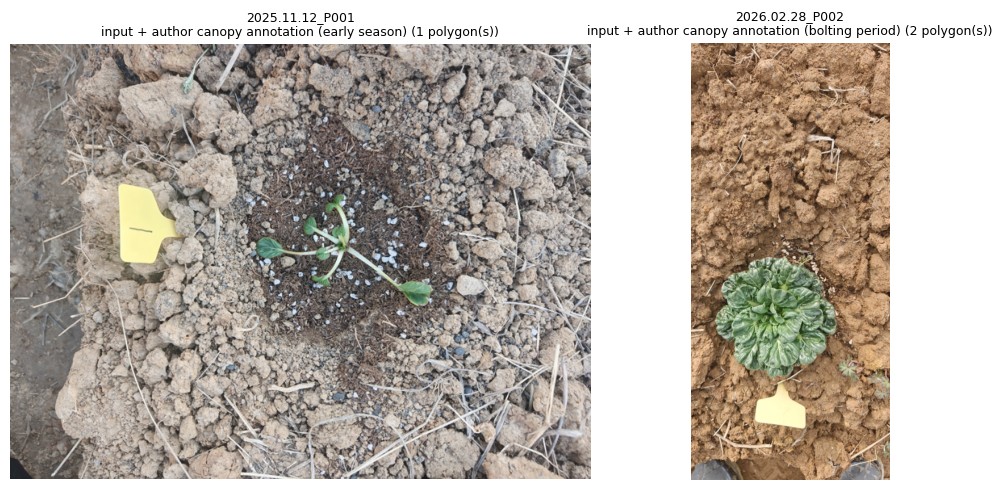

annotation dates: 2025-11-12 and 2026-02-28


In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

def annotated_preview(image_path, out_path, title):
    with Image.open(ROOT / image_path) as im:
        im = im.convert("RGB")
        overlay = im.copy()
        draw = ImageDraw.Draw(overlay)
        ann = json.load(open(ROOT / image_path.replace("images/", "annotations/labelme_json/").replace(".jpg", ".json")))
        n_polys = 0
        for shape in ann["shapes"]:
            if shape.get("label") == "tatsoi_canopy":
                pts = [(float(x), float(y)) for x, y in shape["points"]]
                if len(pts) >= 3:
                    draw.polygon(pts, outline=(255, 40, 40))
                    n_polys += 1
        scale = 720 / max(im.size)
        overlay = overlay.resize((int(im.width * scale), int(im.height * scale)))
        overlay.save(out_path)
    return overlay, n_polys

early = labels.sort_values("image_id").iloc[0]
late_pool = labels[labels["bolting_flowering"] == 1].sort_values("image_id")
late = late_pool.iloc[0]
print("early sample:", early.image_id, "| late sample:", late.image_id,
      "| compactness", early.compactness_score, "->", late.compactness_score)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, row, tag in [(axes[0], early, "input + author canopy annotation (early season)"),
                     (axes[1], late, "input + author canopy annotation (bolting period)")]:
    ov, n_polys = annotated_preview(row.image_path, f"/content/preview_{row.image_id}.png", tag)
    ax.imshow(ov)
    ax.set_title(f"{row.image_id}\n{tag} ({n_polys} polygon(s))", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/tatsoi_input_preview.png", dpi=110, bbox_inches="tight")
plt.show()
print("annotation dates:", early.date, "and", late.date)

### Extract the 27 canopy morphology + color features with the authors' code

We import `extract_one_feature` from the authors' bundled `run_baseline_models.py` (loaded directly from the extracted file, unmodified) and apply it to all 3,456 images. For each image it draws the `tatsoi_canopy` polygon mask, computes canopy area/bbox/shape descriptors, and RGB/green-excess/VARI statistics inside the mask. The only adaptation is a 2-process `multiprocessing` pool to shorten the serial loop (~25–45 min → ~12–25 min); each image is processed by the identical author function, and results are cached to `image_features.csv` in the authors' cache format.
著者コードの `extract_one_feature` を全 3,456 枚に適用します (2 プロセス並列化のみ変更、計算内容は同一)。

In [ ]:
import importlib.util
import multiprocessing as mp
from functools import partial

spec = importlib.util.spec_from_file_location(
    "run_baseline_models", ROOT / "scripts" / "run_baseline_models.py")
rbm = importlib.util.module_from_spec(spec)
sys.modules["run_baseline_models"] = rbm
spec.loader.exec_module(rbm)
print("author script imported; n target traits:", len(rbm.TARGET_COLUMNS))

cache = ROOT / "results" / "image_features.csv"
cache.parent.mkdir(exist_ok=True)
if cache.exists():
    features = pd.read_csv(cache)
    print("loaded cached features:", features.shape)
else:
    started = time.time()
    worker = partial(rbm.extract_one_feature, dataset_root=ROOT)
    with mp.get_context("fork").Pool(processes=2) as pool:
        rows = []
        for i, feats in enumerate(pool.imap_unordered(worker, [r for _, r in labels.iterrows()]), 1):
            rows.append(feats)
            if i % 250 == 0:
                rate = i / max(time.time() - started, 1e-9)
                print(f"extracted {i}/3456 images ({rate:.1f} img/s, {time.time()-started:.0f}s)", flush=True)
    features = pd.DataFrame(rows).sort_values("image_id").reset_index(drop=True)
    features.to_csv(cache, index=False)
    print(f"feature extraction took {time.time()-started:.0f}s")

feature_cols = [c for c in features.columns if c != "image_id"]
print("features:", features.shape, "| columns:", len(feature_cols))
display(features[["image_id"] + feature_cols[:8]].head(3))

author script imported; n target traits: 7


extracted 250/3456 images (2.5 img/s, 100s)


extracted 500/3456 images (2.5 img/s, 200s)


extracted 750/3456 images (2.5 img/s, 296s)


extracted 1000/3456 images (2.5 img/s, 395s)


extracted 1250/3456 images (2.5 img/s, 493s)


... (6 outputs left out)

extracted 3000/3456 images (2.5 img/s, 1179s)


extracted 3250/3456 images (2.5 img/s, 1277s)


feature extraction took 1347s
features: (3456, 29) | columns: 28


,image_id,image_width,image_height,canopy_shape_count,canopy_vertex_count,canopy_area_px,canopy_area_ratio,canopy_perimeter_norm,bbox_width_ratio
0,2025.11.12_P001,4096.0,3072.0,1.0,124.0,135411.0,0.010761,1.449193,0.302246
1,2025.11.12_P002,4096.0,3072.0,1.0,116.0,148207.0,0.011778,0.922743,0.166016
2,2025.11.12_P003,4096.0,3072.0,1.0,159.0,199227.0,0.015833,1.995615,0.229492


### Image-only baseline on the three released splits (authors' evaluation code)

We call the authors' `evaluate()` unchanged for each split column of `splits.csv`. For every trait it trains Dummy / logistic regression (class-weighted) / random forest (300 trees, class-weighted) / HistGradientBoosting on the train subset and reports accuracy, balanced accuracy and macro-F1 on the validation and test subsets. The paper's headline reference for this baseline is the **plant-holdout test mean macro-F1 of 0.828** (mean over the seven traits, best model).
著者の `evaluate()` を 3 分割それぞれに対してそのまま実行します。論文の参照値は plant_holdout テストの平均 macro-F1 0.828 です。

In [ ]:


metrics_image_only = {}
for split_name in ["random", "temporal", "plant_holdout"]:
    metrics_image_only[split_name] = rbm.evaluate(labels, features, splits, split_name)
    n_rows = len(metrics_image_only[split_name])
    print(split_name, "->", n_rows, "result rows")

ph_test = metrics_image_only["plant_holdout"]
ph_test = ph_test[(ph_test["subset"] == "test") & (ph_test["model"] != "not_run_single_training_class")]
mean_f1 = ph_test.groupby("model")["macro_f1"].mean().sort_values(ascending=False)
print("\nplant_holdout test mean macro-F1 over the 7 traits (image-only):")
display(mean_f1.round(4).to_frame())
best_image_only = float(mean_f1.iloc[0])
print(f"best model: {mean_f1.index[0]} -> mean macro-F1 {best_image_only:.3f} (paper Table 4: 0.828)")

random -> 56 result rows


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


... (6 outputs left out)

temporal -> 50 result rows


plant_holdout -> 56 result rows

plant_holdout test mean macro-F1 over the 7 traits (image-only):


,macro_f1
model,
hist_gradient_boosting,0.8282
random_forest,0.8282
logistic_regression,0.7962
dummy_most_frequent,0.4096


best model: hist_gradient_boosting -> mean macro-F1 0.828 (paper Table 4: 0.828)


### Add the 96 environmental features (paper Table 4 comparison) — AI-assisted extension

The released `run_baseline_models.py` covers the image-only half of Table 4; the released benchmark library (`tatsoi_benchmark/dataset.py`, `load_environment_features`) defines the 96 environmental columns used for training. To reproduce the paper's environment-added comparison (plant-holdout mean macro-F1 **0.874**), we merge those 96 columns into the feature frame and rerun the **same authors' `evaluate()`**. This glue (merge only) is AI-assisted; the feature definitions, imputation (train median via the pipeline) and evaluation are the authors' own code.
96 個の環境特徴量を著者ライブラリの定義どおりに結合し、同じ `evaluate()` で再評価します (この結合部分のみ AI による補助実装)。

In [ ]:
env_spec = importlib.util.spec_from_file_location(
    "tatsoi_benchmark_dataset", CODE / "tatsoi_benchmark" / "dataset.py")
tbd = importlib.util.module_from_spec(env_spec)
env_spec.loader.exec_module(tbd)

merged_labels, env_feature_cols = tbd.load_environment_features(labels, ROOT)
print("environment columns used:", len(env_feature_cols))
env_frame = merged_labels[["image_id"] + env_feature_cols]
features_plus_env = features.merge(env_frame, on="image_id", how="inner")
print("extended feature frame:", features_plus_env.shape)

metrics_plus_env = {}
for split_name in ["random", "temporal", "plant_holdout"]:
    metrics_plus_env[split_name] = rbm.evaluate(labels, features_plus_env, splits, split_name)

ph_test_env = metrics_plus_env["plant_holdout"]
ph_test_env = ph_test_env[(ph_test_env["subset"] == "test") & (ph_test_env["model"] != "not_run_single_training_class")]
mean_f1_env = ph_test_env.groupby("model")["macro_f1"].mean().sort_values(ascending=False)
print("\nplant_holdout test mean macro-F1 over the 7 traits (image + environment):")
display(mean_f1_env.round(4).to_frame())
best_plus_env = float(mean_f1_env.iloc[0])
print(f"best model: {mean_f1_env.index[0]} -> mean macro-F1 {best_plus_env:.3f} (paper Table 4: 0.874)")

environment columns used: 96
extended feature frame: (3456, 125)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


... (5 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(



plant_holdout test mean macro-F1 over the 7 traits (image + environment):


,macro_f1
model,
hist_gradient_boosting,0.8737
random_forest,0.8662
logistic_regression,0.8098
dummy_most_frequent,0.4096


best model: hist_gradient_boosting -> mean macro-F1 0.874 (paper Table 4: 0.874)


### Results table and per-trait comparison

We assemble the plant-holdout test macro-F1 per trait and model (image-only vs image+environment) into one table and a grouped bar chart. The chart is an additional visualization created for this notebook (not an author figure); it makes the paper's key finding — environmental features help most where canopy appearance alone is ambiguous — directly inspectable. All metrics are also exported to CSV.
plant_holdout テストの macro-F1 を表と棒グラフにまとめ、CSV にも保存します (グラフは本ノートブック独自の追加可視化です)。

,target,model,macro_f1_image_only,macro_f1_plus_env
0,bolting_flowering,dummy_most_frequent,0.491,0.491
1,bolting_flowering,hist_gradient_boosting,0.977,0.977
2,bolting_flowering,logistic_regression,0.977,0.977
3,bolting_flowering,random_forest,0.977,0.977
4,broken,dummy_most_frequent,0.477,0.477
5,broken,hist_gradient_boosting,0.782,0.867
6,broken,logistic_regression,0.643,0.645
7,broken,random_forest,0.789,0.854
8,chlorosis,dummy_most_frequent,0.347,0.347
9,chlorosis,hist_gradient_boosting,0.805,0.910


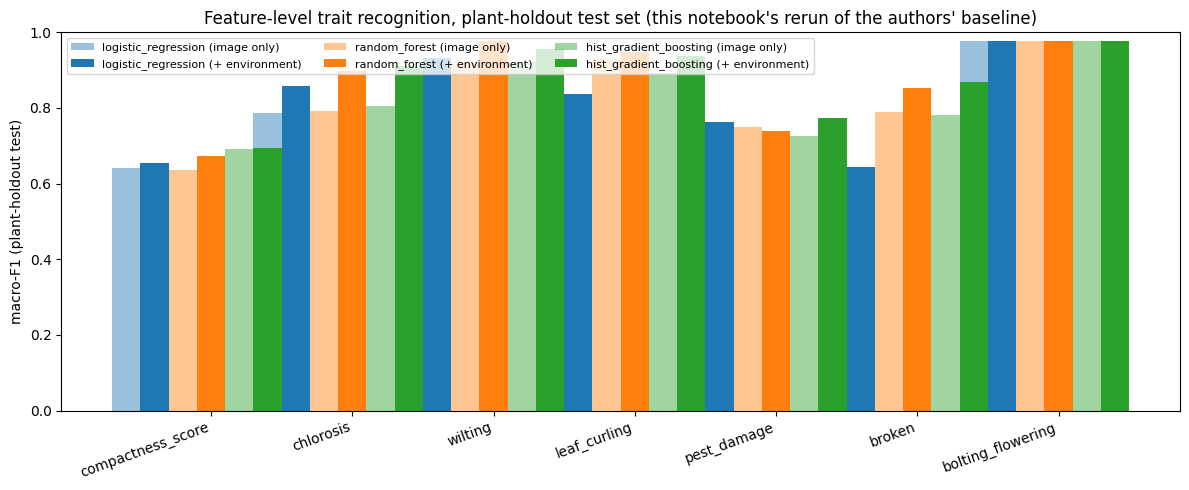

paper reference: mean macro-F1 0.828 (image-only) -> 0.874 (+environment); this run: 0.828 -> 0.874


In [ ]:
summary = ph_test[["target", "model", "macro_f1"]].merge(
    ph_test_env[["target", "model", "macro_f1"]], on=["target", "model"],
    suffixes=("_image_only", "_plus_env"), how="outer")
display(summary.round(3))
summary.to_csv("/content/tatsoi_baseline_plant_holdout_test.csv", index=False)

def f1_of(df, target, model, col):
    sel = df[(df.target == target) & (df.model == model)]
    return float(sel[col].iloc[0]) if len(sel) else float("nan")

fig, ax = plt.subplots(figsize=(12, 5))
targets = rbm.TARGET_COLUMNS
x = np.arange(len(targets))
width = 0.2
for k, model in enumerate(["logistic_regression", "random_forest", "hist_gradient_boosting"]):
    io_vals = [f1_of(summary, t, model, "macro_f1_image_only") for t in targets]
    env_vals = [f1_of(summary, t, model, "macro_f1_plus_env") for t in targets]
    ax.bar(x + (2 * k) * width, io_vals, width, label=f"{model} (image only)", color=f"C{k}", alpha=0.45)
    ax.bar(x + (2 * k + 1) * width, env_vals, width, label=f"{model} (+ environment)", color=f"C{k}")
ax.set_xticks(x + width * 3)
ax.set_xticklabels(targets, rotation=20, ha="right")
ax.set_ylabel("macro-F1 (plant-holdout test)")
ax.set_ylim(0, 1.0)
ax.set_title("Feature-level trait recognition, plant-holdout test set (this notebook's rerun of the authors' baseline)")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.savefig("/content/tatsoi_baseline_results.png", dpi=110, bbox_inches="tight")
plt.show()
print("paper reference: mean macro-F1 0.828 (image-only) -> 0.874 (+environment); "
      f"this run: {best_image_only:.3f} -> {best_plus_env:.3f}")

### Interpretation and validation record

**What was executed**: the authors' own feature-level baseline script on the full released dataset (3,456 images), with the authors' exact feature definitions, models, seed (42), splits, and evaluation code; plus the environment-feature comparison assembled from the authors' released environment tables and evaluation function. The observed plant-holdout test mean macro-F1 (printed above) can be compared with the paper's published 0.828 (image-only) and 0.874 (image+environment). Small differences are expected: the paper reports its own run of the same pipeline, and tree-based models vary slightly with library versions.

**Known limitations**: (1) the deep-learning benchmarks of the paper (Section 3.3–3.5) are not reproduced here; (2) the +environment step is a merge-level extension, labeled above, though it reuses only author-released columns and code; (3) a single-seed rerun is not a statistical replication.

**Provenance**: paper DOI 10.3389/fpls.2026.1978055; dataset Mendeley DOIs 10.17632/2kfszcxhw6.1 (part00 + code + part01), 10.17632/rvd2mxrrxj.1 (part02), 10.17632/657hywkz9x.1 (part03), 10.17632/286gv4tmrh.1 (part04), all verified by SHA-256 at download; author baseline code `scripts/run_baseline_models.py` (sha256 25376b13…4f161) and `tatsoi_benchmark/dataset.py` bundled with the dataset. Dataset license CC BY-NC 4.0 (Part 1) / CC BY 4.0 (image parts) — check reuse terms before redistribution.

**検証の記録**: 著者公開コードとデータセット (SHA-256 検証済み) を用いて特徴量レベル・ベースラインを全画像で再実行しました。深層学習ベンチマークは対象外です。